# GermaNet Data Exploration

This notebook explores the processed GermaNet v1.90 data for the German Word Sense Disambiguation project.

## Dataset Overview

We have 4 main tables:
- **synsets**: Semantic concepts/senses
- **lexical_units**: Words/lemmas within synsets  
- **relations**: Semantic relationships between synsets
- **lemma_senses**: Joined view for WSD tasks


**Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
from collections import Counter

# Set up plotting
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)

print("Libraries loaded successfully!")

Libraries loaded successfully!


**Standard auxilliary methods**

In [37]:
# Handle both empty lists and empty arrays safely
def has_content(item):
    """Check if item has content (works for lists, arrays, None)."""
    if item is None:
        return False
    try:
        return len(item) > 0
    except:
        return False

def count_total_items(series):
    """Count total items across all entries in a series of lists."""
    total = 0
    for item in series:
        if has_content(item):
            total += len(item)
    return total

## Data Loading

In [27]:
# Load processed data
data_dir = Path('../../data/processed/germanet_v190')

# Load all tables
synsets = pd.read_parquet(data_dir / 'synsets.parquet')
lexical_units = pd.read_parquet(data_dir / 'lexical_units.parquet')
relations = pd.read_parquet(data_dir / 'relations.parquet')
lemma_senses = pd.read_parquet(data_dir / 'lemma_senses.parquet')

print(f"✅ Loaded 4 tables:")
print(f"   \t synsets: {len(synsets):,} rows")
print(f"   \t lexical_units: {len(lexical_units):,} rows")
print(f"   \t relations: {len(relations):,} rows")
print(f"   \t lemma_senses: {len(lemma_senses):,} rows")

✅ Loaded 4 tables:
   	 synsets: 174,579 rows
   	 lexical_units: 225,000 rows
   	 relations: 189,330 rows
   	 lemma_senses: 224,999 rows


# Basic Statistics

## Sysnet

In [31]:
print("=== SYNSETS TABLE ===")
print(f"Shape: {synsets.shape}")
print(f"\nColumns: {list(synsets.columns)}")

print(f"\n--- POS Distribution ---")
pos_counts = synsets['pos'].value_counts()
pos_percentages = synsets['pos'].value_counts(normalize=True) * 100

print("Counts:")
for pos in pos_counts.index:
    count = pos_counts[pos]
    percentage = pos_percentages[pos]
    print(f"  {pos}: {count:,} ({percentage:.1f}%)")

print(f"\n--- Paraphrases Available ---")
paraphrase_stats = synsets['paraphrase'].notna().value_counts()
total_synsets = len(synsets)

with_paraphrase = paraphrase_stats.get(True, 0)
without_paraphrase = paraphrase_stats.get(False, 0)
with_paraphrase_pct = (with_paraphrase / total_synsets) * 100
without_paraphrase_pct = (without_paraphrase / total_synsets) * 100

print(f"With paraphrase: {with_paraphrase:,} ({with_paraphrase_pct:.1f}%)")
print(f"Without paraphrase: {without_paraphrase:,} ({without_paraphrase_pct:.1f}%)")

print(f"\nFirst 5 rows:")
display(synsets.head())

=== SYNSETS TABLE ===
Shape: (174579, 4)

Columns: ['synset_id', 'pos', 'class', 'paraphrase']

--- POS Distribution ---
Counts:
  NOUN: 140,296 (80.4%)
  ADJ: 17,525 (10.0%)
  VERB: 16,758 (9.6%)

--- Paraphrases Available ---
With paraphrase: 8,302 (4.8%)
Without paraphrase: 166,277 (95.2%)

First 5 rows:


,synset_id,pos,class,paraphrase
0,s10316,NOUN,Pflanze,None
1,s12191,NOUN,Pflanze,None
2,s12192,NOUN,Pflanze,None
3,s12193,NOUN,Pflanze,None
4,s26477,NOUN,Pflanze,None


## Lexical Units

In [34]:
print("=== LEXICAL UNITS TABLE ===")
print(f"Shape: {lexical_units.shape}")
print(f"\nColumns: {list(lexical_units.columns)}")

print(f"\n--- Unique Lemmas ---")
unique_lemmas = lexical_units['lemma'].nunique()
total_lexunits = len(lexical_units)
print(f"Total unique lemmas: {unique_lemmas:,}")
print(f"Total lexical units: {total_lexunits:,}")
print(f"Average lexical units per lemma: {total_lexunits/unique_lemmas:.2f}")

print(f"\n--- Variants & Examples ---")

has_variants = sum(has_content(v) for v in lexical_units['variants'])
has_examples = sum(has_content(e) for e in lexical_units['examples'])
variants_pct = (has_variants / total_lexunits) * 100
examples_pct = (has_examples / total_lexunits) * 100

print(f"Lexical units with variants: {has_variants:,} ({variants_pct:.1f}%)")
print(f"Lexical units with examples: {has_examples:,} ({examples_pct:.1f}%)")

print(f"\n--- Flags ---")
named_entities = lexical_units['named_entity'].sum()
artificial = lexical_units['artificial'].sum()
style_marking = lexical_units['style_marking'].sum()

named_entities_pct = (named_entities / total_lexunits) * 100
artificial_pct = (artificial / total_lexunits) * 100
style_marking_pct = (style_marking / total_lexunits) * 100

print(f"Named entities: {named_entities:,} ({named_entities_pct:.1f}%)")
print(f"Artificial: {artificial:,} ({artificial_pct:.1f}%)")
print(f"Style marking: {style_marking:,} ({style_marking_pct:.1f}%)")

print(f"\n--- POS Distribution ---")
pos_counts = lexical_units['pos'].value_counts()
print("Absolute counts:")
print(pos_counts)
print("\nRelative percentages:")
for pos in pos_counts.index:
    count = pos_counts[pos]
    percentage = (count / total_lexunits) * 100
    print(f"  {pos}: {count:,} ({percentage:.1f}%)")

print(f"\nFirst 5 rows:")
display(lexical_units.head())

=== LEXICAL UNITS TABLE ===
Shape: (225000, 12)

Columns: ['lexunit_id', 'synset_id', 'lemma', 'variants', 'named_entity', 'artificial', 'style_marking', 'examples', 'pos', 'class', 'sense', 'source']

--- Unique Lemmas ---
Total unique lemmas: 202,745
Total lexical units: 225,000
Average lexical units per lemma: 1.11

--- Variants & Examples ---
Lexical units with variants: 3,891 (1.7%)
Lexical units with examples: 22,080 (9.8%)

--- Flags ---
Named entities: 3,184 (1.4%)
Artificial: 541 (0.2%)
Style marking: 1,287 (0.6%)

--- POS Distribution ---
Absolute counts:
pos
NOUN    181047
VERB     22003
ADJ      21950
Name: count, dtype: int64

Relative percentages:
  NOUN: 181,047 (80.5%)
  VERB: 22,003 (9.8%)
  ADJ: 21,950 (9.8%)

First 5 rows:


,lexunit_id,synset_id,lemma,variants,named_entity,artificial,style_marking,examples,pos,class,sense,source
0,l14371,s10316,Hecke,[],False,False,False,[],NOUN,Pflanze,2,core
1,l14372,s10316,Hag,[],False,False,True,[],NOUN,Pflanze,1,core
2,l16885,s12191,Kerngehäuse,[],False,False,False,[],NOUN,Pflanze,1,core
3,l100985,s12191,Gehäuse,[],False,False,False,[],NOUN,Pflanze,1,core
4,l16886,s12192,Apfelgehäuse,[],False,False,False,[],NOUN,Pflanze,1,core


## Relations

In [35]:
print("=== RELATIONS TABLE ===")
print(f"Shape: {relations.shape}")
print(f"\nColumns: {list(relations.columns)}")
print(f"\nFirst 5 rows:")
display(relations.head())

total_relations = len(relations)
print(f"\nTotal semantic relations: {total_relations:,}")

print(f"\n--- Relation Types ---")
relation_counts = relations['relation_type'].value_counts()
print("Top 15 relation types:")
print("Absolute counts:")
for i, (rel_type, count) in enumerate(relation_counts.head(15).items()):
    percentage = (count / total_relations) * 100
    print(f"  {rel_type}: {count:,} ({percentage:.1f}%)")

print(f"\n--- Direction Analysis ---")
direction_counts = relations['direction'].value_counts()
print("Direction distribution:")
for direction, count in direction_counts.items():
    percentage = (count / total_relations) * 100
    print(f"  {direction}: {count:,} ({percentage:.1f}%)")

print(f"\n--- Network Coverage ---")
unique_from_synsets = relations['from_synset'].nunique()
unique_to_synsets = relations['to_synset'].nunique()
all_relation_synsets = len(set(relations['from_synset']) | set(relations['to_synset']))

print(f"Synsets as source (from): {unique_from_synsets:,}")
print(f"Synsets as target (to): {unique_to_synsets:,}")
print(f"Total synsets in relations: {all_relation_synsets:,}")

# Compare with total synsets if available
if 'synsets' in globals():
    total_synsets = len(synsets)
    coverage_pct = (all_relation_synsets / total_synsets) * 100
    print(f"Synsets covered by relations: {all_relation_synsets:,} / {total_synsets:,} ({coverage_pct:.1f}%)")

print(f"\n--- Relation Density ---")
avg_relations_per_synset = total_relations / all_relation_synsets
print(f"Average relations per synset: {avg_relations_per_synset:.2f}")

# Most connected synsets
print(f"\n--- Most Connected Synsets ---")
synset_connections = {}
for _, row in relations.iterrows():
    from_synset = row['from_synset']
    to_synset = row['to_synset']
    synset_connections[from_synset] = synset_connections.get(from_synset, 0) + 1
    synset_connections[to_synset] = synset_connections.get(to_synset, 0) + 1

most_connected = sorted(synset_connections.items(), key=lambda x: x[1], reverse=True)[:10]
print("Top 10 most connected synsets:")
for synset, connection_count in most_connected:
    print(f"  {synset}: {connection_count} connections")

=== RELATIONS TABLE ===
Shape: (189330, 5)

Columns: ['relation_type', 'from_synset', 'to_synset', 'direction', 'inverse']

First 5 rows:


,relation_type,from_synset,to_synset,direction,inverse
0,has_hypernym,s0,s51001,revert,has_hyponym
1,has_hypernym,s1,s0,revert,has_hyponym
2,has_hypernym,s2,s1,revert,has_hyponym
3,has_hypernym,s4,s2,revert,has_hyponym
4,has_hypernym,s5,s1,revert,has_hyponym



Total semantic relations: 189,330

--- Relation Types ---
Top 15 relation types:
Absolute counts:
  has_hypernym: 179,520 (94.8%)
  has_component_meronym: 4,902 (2.6%)
  is_related_to: 2,967 (1.6%)
  has_substance_meronym: 824 (0.4%)
  has_member_meronym: 691 (0.4%)
  has_portion_meronym: 216 (0.1%)
  causes: 186 (0.1%)
  entails: 24 (0.0%)

--- Direction Analysis ---
Direction distribution:
  revert: 186,177 (98.3%)
  both: 2,967 (1.6%)
  one: 186 (0.1%)

--- Network Coverage ---
Synsets as source (from): 174,578
Synsets as target (to): 32,884
Total synsets in relations: 174,579
Synsets covered by relations: 174,579 / 174,579 (100.0%)

--- Relation Density ---
Average relations per synset: 1.08

--- Most Connected Synsets ---
Top 10 most connected synsets:
  s43645: 570 connections
  s3215: 465 connections
  s13220: 347 connections
  s44177: 283 connections
  s19428: 275 connections
  s13704: 270 connections
  s46350: 258 connections
  s18413: 254 connections
  s32542: 246 connection

## Lemma Senses

In [38]:
print("=== LEMMA SENSES TABLE (WSD-ready) ===")
print(f"Shape: {lemma_senses.shape}")
print(f"\nColumns: {list(lemma_senses.columns)}")

print(f"\n--- Polysemy Analysis ---")
senses_per_lemma = lemma_senses.groupby('lemma').size()
total_lemma_senses = len(lemma_senses)
unique_lemmas_in_senses = lemma_senses['lemma'].nunique()

print(f"Total lemma-sense pairs: {total_lemma_senses:,}")
print(f"Unique lemmas: {unique_lemmas_in_senses:,}")
print(f"Average senses per lemma: {senses_per_lemma.mean():.2f}")
print(f"Max senses for a single lemma: {senses_per_lemma.max()}")

print(f"\nPolysemy distribution:")
polysemy_dist = senses_per_lemma.value_counts().head(10)
for num_senses, count in polysemy_dist.items():
    percentage = (count / unique_lemmas_in_senses) * 100
    print(f"  {num_senses} sense(s): {count:,} lemmas ({percentage:.1f}%)")

print(f"\n--- Content Richness in Lemma-Senses ---")
# Paraphrases
senses_with_paraphrase = lemma_senses['paraphrase'].notna().sum()
paraphrase_coverage = (senses_with_paraphrase / total_lemma_senses) * 100
print(f"Lemma-senses with paraphrases: {senses_with_paraphrase:,} ({paraphrase_coverage:.1f}%)")

# Variants
senses_with_variants = sum(has_content(v) for v in lemma_senses['variants'])
total_variants = count_total_items(lemma_senses['variants'])
variant_coverage = (senses_with_variants / total_lemma_senses) * 100
print(f"Lemma-senses with variants: {senses_with_variants:,} ({variant_coverage:.1f}%)")
print(f"Total variant forms: {total_variants:,}")

# Examples
senses_with_examples = sum(has_content(e) for e in lemma_senses['examples'])
total_examples = count_total_items(lemma_senses['examples'])
example_coverage = (senses_with_examples / total_lemma_senses) * 100
print(f"Lemma-senses with examples: {senses_with_examples:,} ({example_coverage:.1f}%)")
print(f"Total example sentences: {total_examples:,}")

print(f"\n--- POS Distribution in Lemma-Senses ---")
pos_counts = lemma_senses['pos'].value_counts()
print("Absolute counts:")
print(pos_counts)
print("\nRelative percentages:")
for pos in pos_counts.index:
    count = pos_counts[pos]
    percentage = (count / total_lemma_senses) * 100
    print(f"  {pos}: {count:,} ({percentage:.1f}%)")

print(f"\nFirst 5 rows:")
display(lemma_senses.head())

=== LEMMA SENSES TABLE (WSD-ready) ===
Shape: (224999, 7)

Columns: ['lemma', 'pos', 'synset_id', 'class', 'paraphrase', 'variants', 'examples']

--- Polysemy Analysis ---
Total lemma-sense pairs: 224,999
Unique lemmas: 202,745
Average senses per lemma: 1.11
Max senses for a single lemma: 26

Polysemy distribution:
  1 sense(s): 187,426 lemmas (92.4%)
  2 sense(s): 11,498 lemmas (5.7%)
  3 sense(s): 2,371 lemmas (1.2%)
  4 sense(s): 759 lemmas (0.4%)
  5 sense(s): 316 lemmas (0.2%)
  6 sense(s): 159 lemmas (0.1%)
  7 sense(s): 81 lemmas (0.0%)
  8 sense(s): 52 lemmas (0.0%)
  9 sense(s): 29 lemmas (0.0%)
  10 sense(s): 21 lemmas (0.0%)

--- Content Richness in Lemma-Senses ---
Lemma-senses with paraphrases: 11,834 (5.3%)
Lemma-senses with variants: 3,891 (1.7%)
Total variant forms: 3,891
Lemma-senses with examples: 22,080 (9.8%)
Total example sentences: 24,491

--- POS Distribution in Lemma-Senses ---
Absolute counts:
pos
NOUN    181046
VERB     22003
ADJ      21950
Name: count, dtype:

,lemma,pos,synset_id,class,paraphrase,variants,examples
0,Hecke,NOUN,s10316,Pflanze,None,[],[]
1,Hag,NOUN,s10316,Pflanze,None,[],[]
2,Kerngehäuse,NOUN,s12191,Pflanze,None,[],[]
3,Gehäuse,NOUN,s12191,Pflanze,None,[],[]
4,Apfelgehäuse,NOUN,s12192,Pflanze,None,[],[]


## 3. Data Visualizations

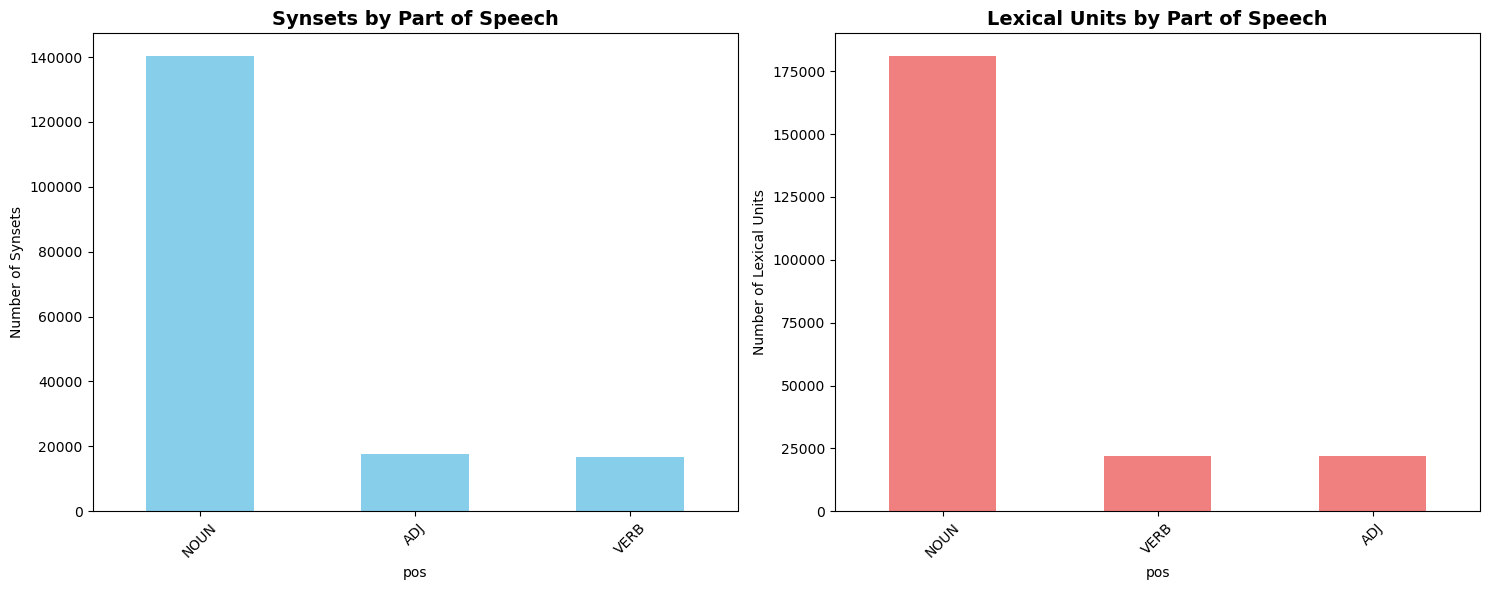

In [39]:
# POS distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Synsets by POS
synsets['pos'].value_counts().plot(kind='bar', ax=ax1, color='skyblue')
ax1.set_title('Synsets by Part of Speech', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Synsets')
ax1.tick_params(axis='x', rotation=45)

# Lexical units by POS
lexical_units['pos'].value_counts().plot(kind='bar', ax=ax2, color='lightcoral')
ax2.set_title('Lexical Units by Part of Speech', fontsize=14, fontweight='bold')
ax2.set_ylabel('Number of Lexical Units')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

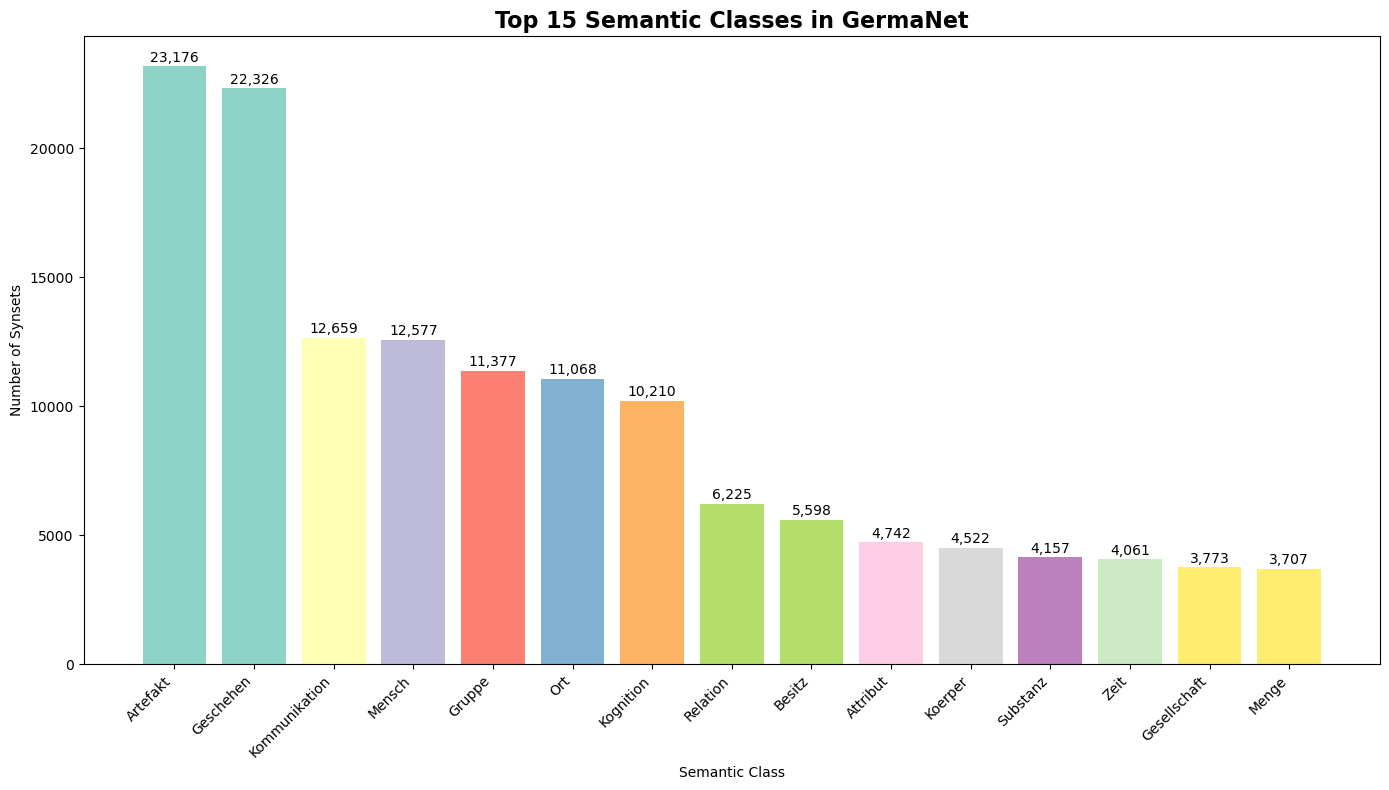

In [40]:
# Top semantic classes
plt.figure(figsize=(14, 8))

top_classes = synsets['class'].value_counts().head(15)
colors = plt.cm.Set3(np.linspace(0, 1, len(top_classes)))

bars = plt.bar(range(len(top_classes)), top_classes.values, color=colors)
plt.title('Top 15 Semantic Classes in GermaNet', fontsize=16, fontweight='bold')
plt.xlabel('Semantic Class')
plt.ylabel('Number of Synsets')
plt.xticks(range(len(top_classes)), top_classes.index, rotation=45, ha='right')

# Add value labels on bars
for bar, value in zip(bars, top_classes.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{value:,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

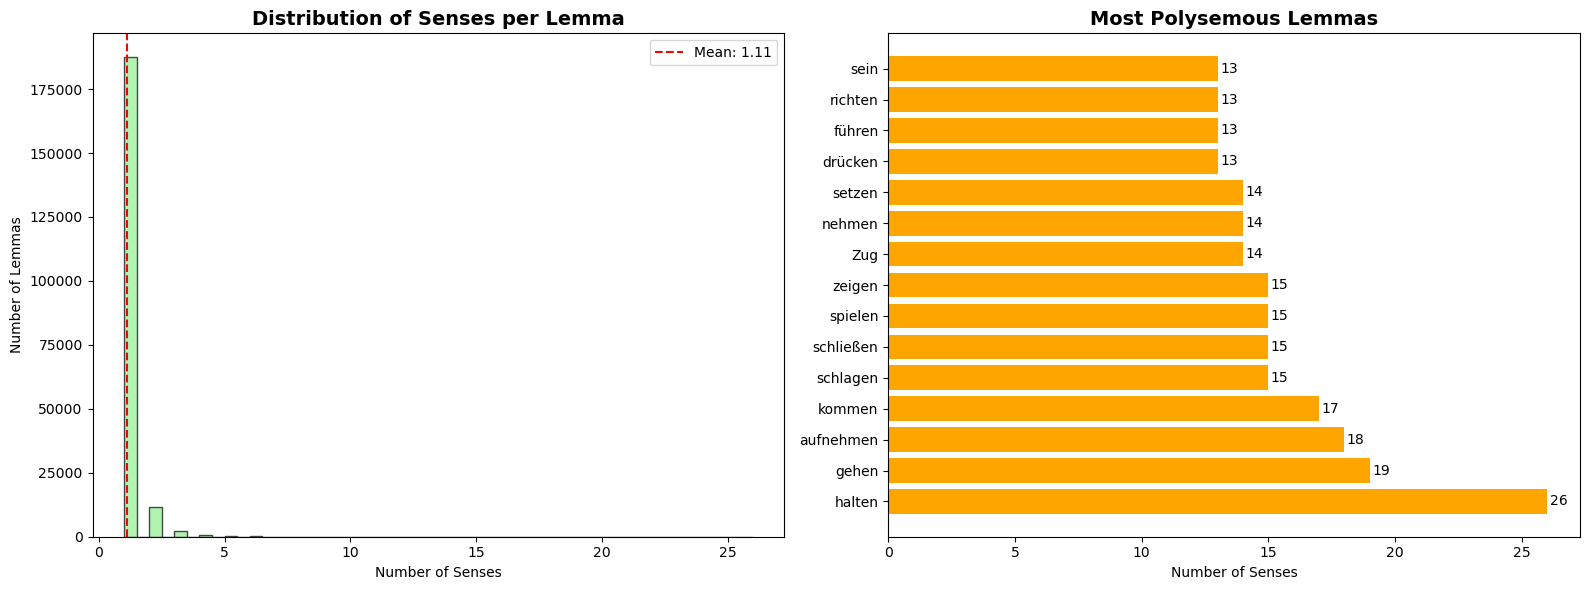

In [41]:
# Polysemy distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Histogram of senses per lemma
senses_per_lemma = lemma_senses.groupby('lemma').size()
ax1.hist(senses_per_lemma, bins=50, color='lightgreen', alpha=0.7, edgecolor='black')
ax1.set_title('Distribution of Senses per Lemma', fontsize=14, fontweight='bold')
ax1.set_xlabel('Number of Senses')
ax1.set_ylabel('Number of Lemmas')
ax1.axvline(senses_per_lemma.mean(), color='red', linestyle='--', 
           label=f'Mean: {senses_per_lemma.mean():.2f}')
ax1.legend()

# Top polysemous words
most_polysemous = senses_per_lemma.nlargest(15)
bars = ax2.barh(range(len(most_polysemous)), most_polysemous.values, color='orange')
ax2.set_title('Most Polysemous Lemmas', fontsize=14, fontweight='bold')
ax2.set_xlabel('Number of Senses')
ax2.set_yticks(range(len(most_polysemous)))
ax2.set_yticklabels(most_polysemous.index)

# Add value labels
for i, (bar, value) in enumerate(zip(bars, most_polysemous.values)):
    ax2.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2, 
             str(value), ha='left', va='center')

plt.tight_layout()
plt.show()

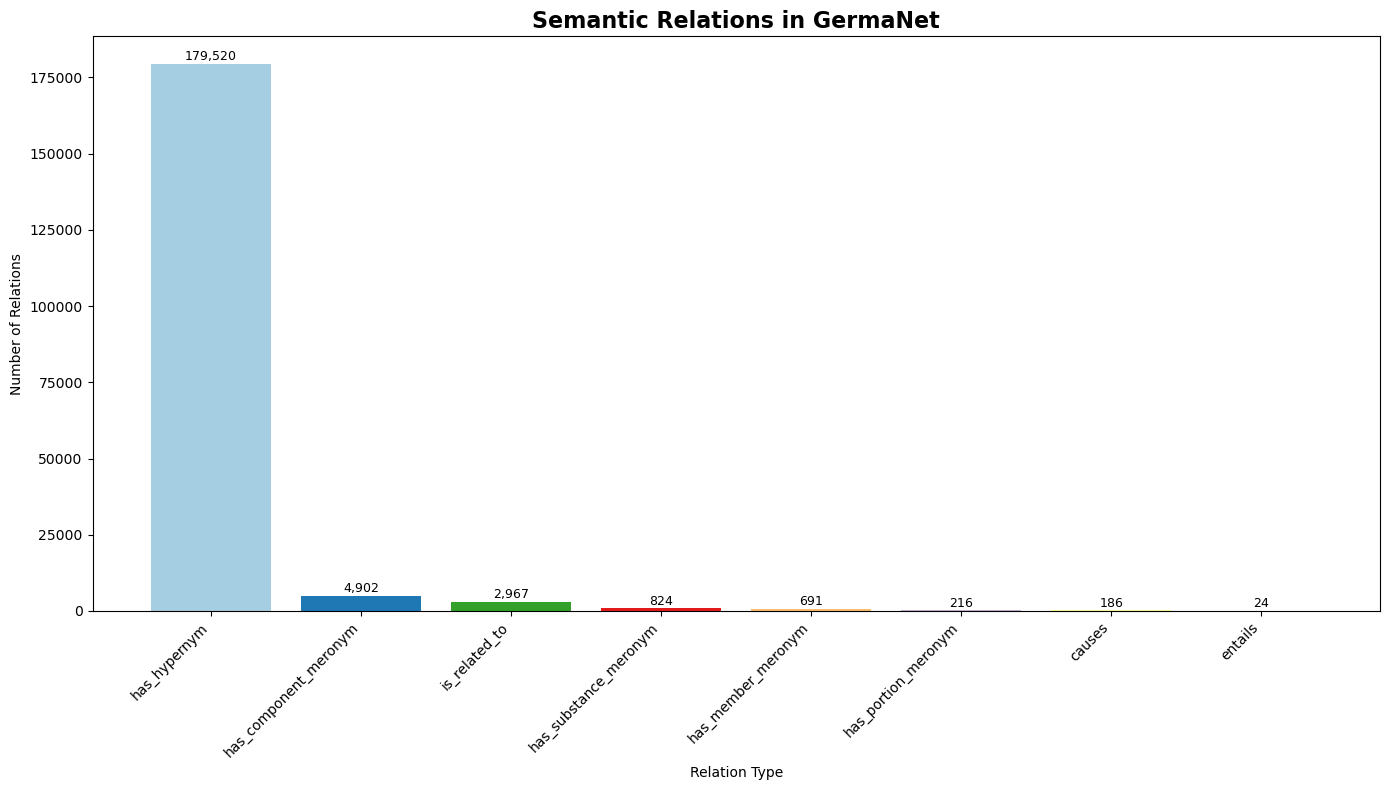

In [42]:
# Semantic relations analysis
plt.figure(figsize=(14, 8))

relation_counts = relations['relation_type'].value_counts().head(12)
colors = plt.cm.Paired(np.linspace(0, 1, len(relation_counts)))

bars = plt.bar(range(len(relation_counts)), relation_counts.values, color=colors)
plt.title('Semantic Relations in GermaNet', fontsize=16, fontweight='bold')
plt.xlabel('Relation Type')
plt.ylabel('Number of Relations')
plt.xticks(range(len(relation_counts)), relation_counts.index, rotation=45, ha='right')

# Add value labels
for bar, value in zip(bars, relation_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, 
             f'{value:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 4. Word Sense Disambiguation Examples

In [44]:
# Function to show senses for a lemma
def show_lemma_senses(lemma, pos=None):
    """Display all senses for a given lemma."""
    query = lemma_senses[lemma_senses['lemma'] == lemma]
    if pos:
        query = query[query['pos'] == pos]
    
    if len(query) == 0:
        print(f"No senses found for '{lemma}' {f'({pos})' if pos else ''}")
        return
    
    print(f"\n=== Senses for '{lemma}' ===\n")
    for idx, row in query.iterrows():
        print(f"Synset: {row['synset_id']} | POS: {row['pos']} | Class: {row['class']}")
        if row['paraphrase']:
            print(f"Definition: {row['paraphrase']}")
        if row['variants'] is not None and len(row['variants']) > 0:
            print(f"Variants: {', '.join(row['variants'])}")
        if row['examples'] is not None and len(row['examples']) > 0:
            print(f"Examples: {'; '.join(row['examples'][:2])}{'...' if len(row['examples']) > 2 else ''}")
        print("-" * 60)

# Examples of polysemous German words
test_words = ['Bank', 'Schloss', 'Zelle', 'Blatt', 'Hahn']

for word in test_words:
    show_lemma_senses(word)


=== Senses for 'Bank' ===

Synset: s69017 | POS: NOUN | Class: Mensch
------------------------------------------------------------
Synset: s25245 | POS: NOUN | Class: Gruppe
------------------------------------------------------------
Synset: s107676 | POS: NOUN | Class: Menge
------------------------------------------------------------
Synset: s6399 | POS: NOUN | Class: Artefakt
------------------------------------------------------------
Synset: s9650 | POS: NOUN | Class: Artefakt
------------------------------------------------------------

=== Senses for 'Schloss' ===

Synset: s6011 | POS: NOUN | Class: Artefakt
------------------------------------------------------------
Synset: s42555 | POS: NOUN | Class: Artefakt
------------------------------------------------------------

=== Senses for 'Zelle' ===

Synset: s41713 | POS: NOUN | Class: Ort
------------------------------------------------------------
Synset: s75874 | POS: NOUN | Class: Gruppe
-----------------------------------

In [ ]:
# Find highly ambiguous nouns for WSD evaluation
noun_senses = lemma_senses[lemma_senses['pos'] == 'NOUN'].groupby('lemma').size()
highly_ambiguous_nouns = noun_senses[noun_senses >= 5].sort_values(ascending=False)

print("=== Top 20 Most Ambiguous NOUNS (5+ senses) ===")
print(f"{'Lemma':<15} {'Senses':<8} {'Sample Classes':<40}")
print("-" * 70)

for lemma, sense_count in highly_ambiguous_nouns.head(20).items():
    classes = lemma_senses[(lemma_senses['lemma'] == lemma) & 
                          (lemma_senses['pos'] == 'NOUN')]['class'].tolist()
    sample_classes = ', '.join(classes[:3]) + ('...' if len(classes) > 3 else '')
    print(f"{lemma:<15} {sense_count:<8} {sample_classes:<40}")

## 5. Data Quality Assessment

In [ ]:
print("=== DATA QUALITY CHECKS ===\n")

# 1. Check for missing synset IDs in relations
all_synset_ids = set(synsets['synset_id'])
relation_synsets = set(relations['from_synset']) | set(relations['to_synset'])
missing_in_relations = relation_synsets - all_synset_ids
print(f"1. Synsets referenced in relations but missing from synsets table: {len(missing_in_relations)}")

# 2. Check join integrity
lexunit_synsets = set(lexical_units['synset_id'])
missing_synsets_for_lexunits = lexunit_synsets - all_synset_ids
print(f"2. Synsets referenced by lexical units but missing: {len(missing_synsets_for_lexunits)}")

# 3. Duplicate checks
duplicate_synsets = synsets['synset_id'].duplicated().sum()
duplicate_lexunits = lexical_units['lexunit_id'].duplicated().sum()
print(f"3. Duplicate synset IDs: {duplicate_synsets}")
print(f"4. Duplicate lexunit IDs: {duplicate_lexunits}")

# 4. Empty lemmas
empty_lemmas = lexical_units['lemma'].isna().sum()
print(f"5. Empty lemmas: {empty_lemmas}")

# Helper function for safe content checking
def has_content(item):
    """Check if item has content (works for lists, arrays, None)."""
    if item is None:
        return False
    try:
        return len(item) > 0
    except:
        return False

# 5. Data completeness
print(f"\n=== COMPLETENESS ===\n")
print(f"Synsets with paraphrases: {synsets['paraphrase'].notna().sum():,} / {len(synsets):,} ({synsets['paraphrase'].notna().mean()*100:.1f}%)")

lexunits_with_examples = sum(has_content(e) for e in lexical_units['examples'])
lexunits_with_variants = sum(has_content(v) for v in lexical_units['variants'])

print(f"Lexical units with examples: {lexunits_with_examples:,} / {len(lexical_units):,} ({lexunits_with_examples/len(lexical_units)*100:.1f}%)")
print(f"Lexical units with variants: {lexunits_with_variants:,} / {len(lexical_units):,} ({lexunits_with_variants/len(lexical_units)*100:.1f}%)")

print(f"\n✅ Data quality looks good for WSD tasks!")

## 6. Summary & Next Steps

This exploration confirms that the processed GermaNet data is well-structured and ready for WSD tasks:


### For WSD Development:
1. Use `lemma_senses` table as primary lookup for sense candidates
2. Leverage semantic classes and relations for context
3. Focus on highly polysemous words for evaluation
4. Consider POS-specific models given the distribution differences

### Recommended Test Cases:
Words like **Bank**, **Schloss**, **Zelle** provide excellent test cases with clear semantic distinctions perfect for evaluating WSD performance.


In [ ]:
# Quick access to key datasets for WSD development
print("=== DATASETS READY FOR WSD ===\n")
print(f"Primary table: lemma_senses ({len(lemma_senses):,} rows)")
print(f"Unique lemmas: {lemma_senses['lemma'].nunique():,}")
print(f"Average polysemy: {lemma_senses.groupby('lemma').size().mean():.2f} senses/lemma")
print(f"\nPOS distribution in lemma_senses:")
print(lemma_senses['pos'].value_counts())
print(f"\nData files location: {data_dir}")
print(f"\n🚀 Ready for BERT-based WSD model development!")